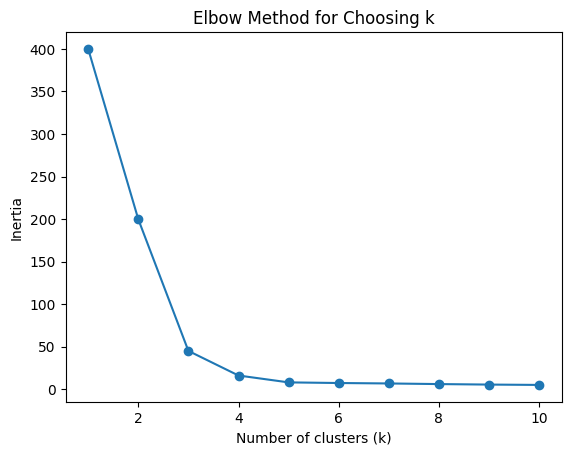

Cluster counts:
0    40
1    40
2    42
3    40
4    38
Name: count, dtype: int64
Silhouette score: 0.736


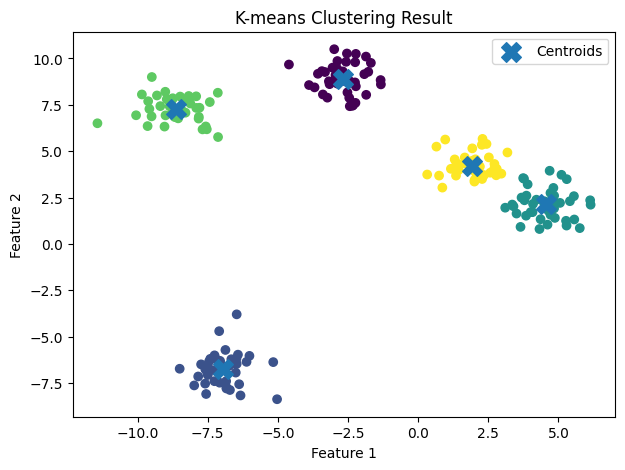

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.datasets import make_blobs

# Generated customer-like data so no external CSV is required.
X, _ = make_blobs(n_samples=200, centers=5, cluster_std=0.8, random_state=42)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)"); plt.ylabel("Inertia")
plt.title("Elbow Method for Choosing k"); plt.show()

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)
print("Cluster counts:")
print(pd.Series(labels).value_counts().sort_index())
print("Silhouette score:", round(silhouette_score(X_scaled, labels), 3))

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels)
plt.scatter(scaler.inverse_transform(kmeans.cluster_centers_)[:, 0],
            scaler.inverse_transform(kmeans.cluster_centers_)[:, 1],
            marker="X", s=200, label="Centroids")
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.title("K-means Clustering Result"); plt.legend(); plt.show()